<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HECKTORRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 3.82MB/s]


Dataset shape: (588, 10)
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

HPV class distribution:
HPV_Label
0     58
1    530
Name: count, dtype: int64

3-fold stratified CV; no test set.

================== FOLD 1/3 ==================
Training: 392 Validation: 196
Training class weights: {0: 5.0256410256410255, 1: 0.5552407932011332}
Selected threshold: 0.865
Accuracy                                       0.7449
Balanced_Accuracy                              0.6708
Precision                                      0.9441
Recall                                         0.7627
F1                                             0.8438
ROC_AUC                                        0.6968
PR_AUC                                         0.9478
Threshold                                      0.8650
N_Train                                      392.0000
N_Validation                                 196.0000
Validation_Bal

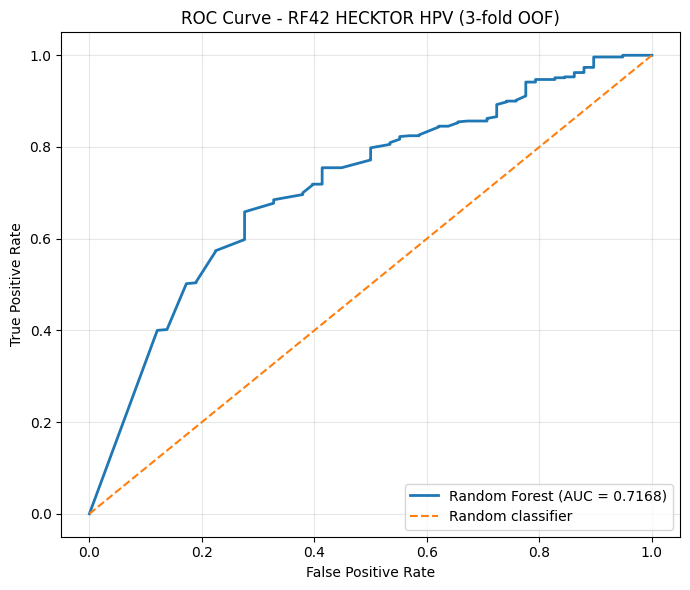

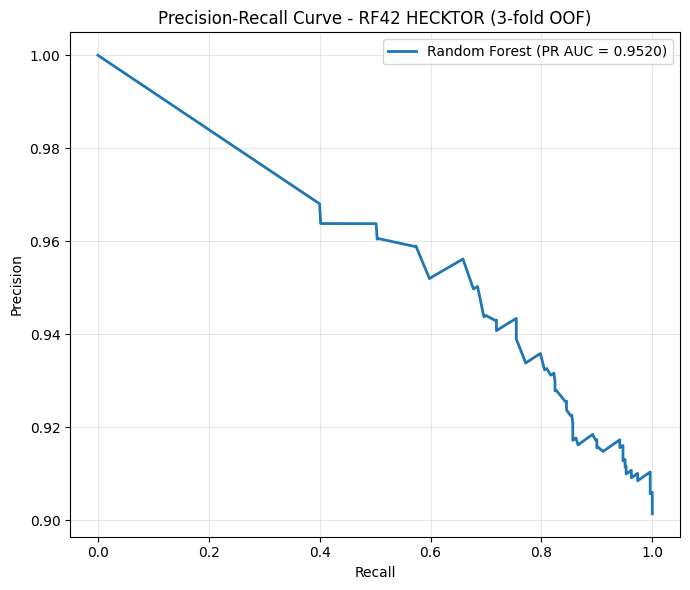


Mean feature importance across folds:
            feature  importance_mean  importance_sd
                Age         0.331509       0.015729
            T-stage         0.240132       0.028840
            N-stage         0.120049       0.001402
Tobacco Consumption         0.094681       0.006102
 Performance Status         0.080460       0.007785
Alcohol Consumption         0.063760       0.004161
             Gender         0.038662       0.004427
            M-stage         0.030746       0.005948


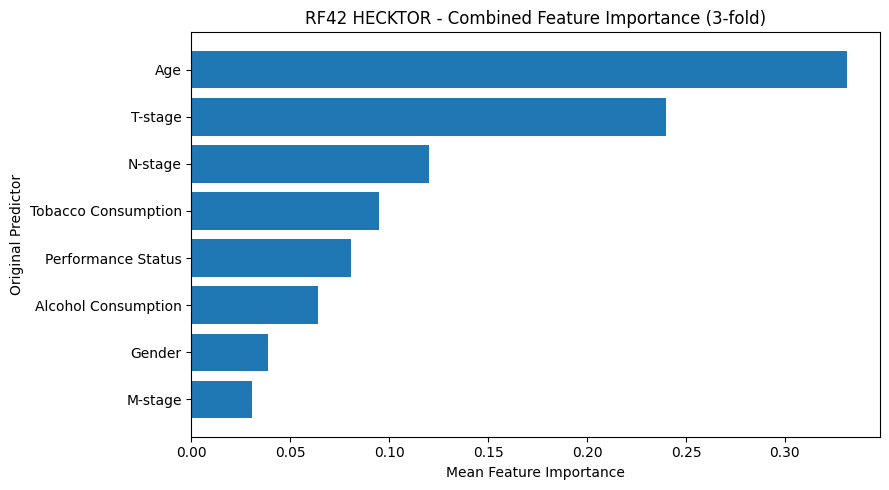

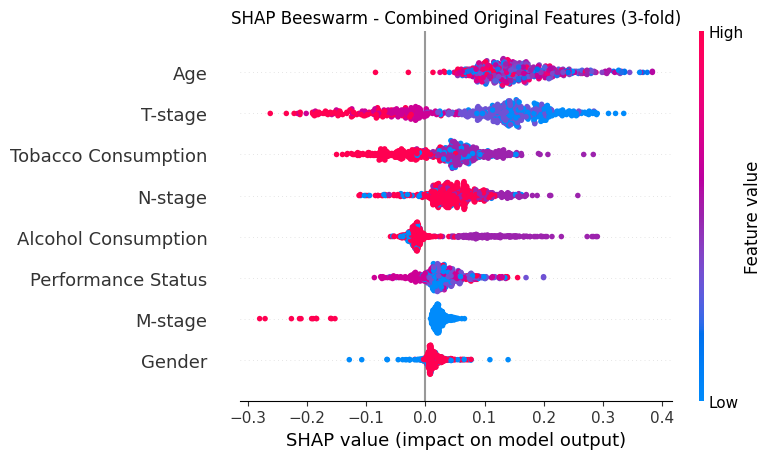


Mean absolute SHAP importance across pooled validation folds:
            feature  mean_abs_SHAP
                Age       0.154376
            T-stage       0.128286
Tobacco Consumption       0.061397
            N-stage       0.059564
Alcohol Consumption       0.046061
 Performance Status       0.037087
            M-stage       0.027140
             Gender       0.016608

Mean absolute LIME contribution across folds:
            feature  mean_abs_LIME  sd_abs_LIME
            T-stage       0.064830     0.010201
Alcohol Consumption       0.020418     0.002272
            N-stage       0.018836     0.001136
Tobacco Consumption       0.017874     0.004984
 Performance Status       0.008311     0.000916
                Age       0.007405     0.004993
             Gender       0.004357     0.002277
            M-stage       0.003255     0.000366


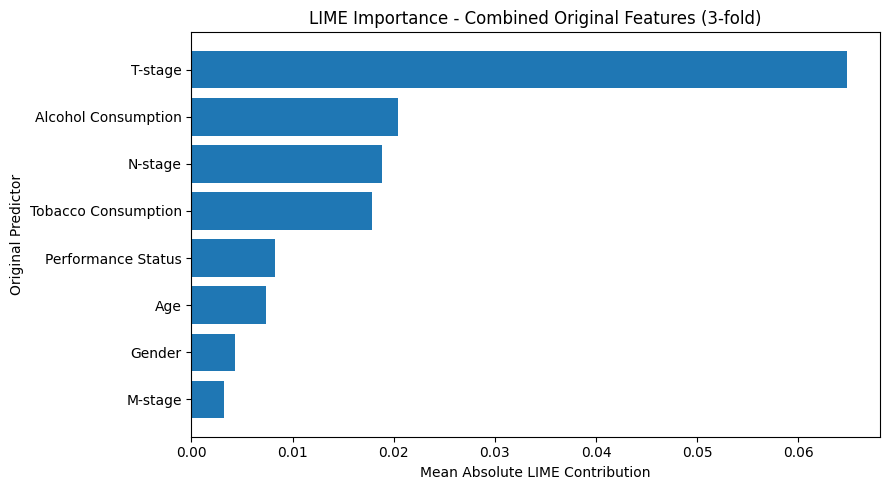


RF42 HECKTOR 3-FOLD CV SUMMARY
Original predictors: 8
Fold models: 3
Trees per fold: 100
Random seed: 42
Split: Stratified 3-fold cross-validation; no test set
SMOTE: Not used
Categorical encoding: OneHotEncoder
Scaling: StandardScaler for Age
Threshold: Selected independently on each validation fold
SHAP: Fold validation contributions pooled; one row per original feature
LIME: Mean absolute grouped contributions across three folds

Pooled out-of-fold metrics:
Accuracy             0.7823
Balanced_Accuracy    0.6566
Precision            0.9370
Recall               0.8132
F1                   0.8707
ROC_AUC              0.7168
PR_AUC               0.9520
Threshold            0.8550

Results saved in: /content/drive/MyDrive/RF_results_HECKTOR_3fold
Analysis complete.


In [1]:
!pip -q install gdown openpyxl shap lime

# ============================================================
# RF42 HECKTOR — Random Forest HPV Classification
# Stratified 3-fold CV; no independent test set
# ============================================================

import os, json, random, warnings, joblib, gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
FILE_ID = "1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv"
DATA_PATH = "HPV2025.xlsx"
if not os.path.exists(DATA_PATH):
    gdown.download(id=FILE_ID, output=DATA_PATH, quiet=False)
df = pd.read_excel(DATA_PATH)
features = ["Age", "Gender", "Tobacco Consumption",
    "Alcohol Consumption", "Performance Status", "T-stage",
    "N-stage", "M-stage"]
target_column = "HPV Status"
if target_column not in df.columns:
    raise KeyError(f"Target column '{target_column}' was not found. "
                   f"Available columns: {df.columns.tolist()}")
missing_features = [col for col in features if col not in df.columns]
if missing_features:
    raise KeyError(f"These predictors are missing from the file: {missing_features}")
df = df.dropna(subset=[target_column]).copy()
target_numeric = pd.to_numeric(df[target_column], errors="coerce")
df = df.loc[target_numeric.isin([0, 1])].copy()
df["HPV_Label"] = pd.to_numeric(df[target_column], errors="coerce").astype(int)
if "PatientID" in df.columns:
    patient_ids = df["PatientID"].copy()
else:
    patient_ids = pd.Series(df.index.astype(str), index=df.index)
model_df = df[features].copy()
model_df["HPV_Label"] = df["HPV_Label"]
model_df["patient_id"] = patient_ids
numeric_features = ["Age"]
categorical_features = [col for col in features if col not in numeric_features]
missing_strings = {"", "nan", "none", "null", "na", "n/a"}
for col in categorical_features:
    model_df[col] = model_df[col].apply(
        lambda value: np.nan if pd.isna(value) or
        str(value).strip().lower() in missing_strings else str(value).strip())
model_df["Age"] = pd.to_numeric(model_df["Age"], errors="coerce")
if model_df["HPV_Label"].nunique() != 2:
    raise ValueError("HPV Status must contain both classes: 0 and 1.")
if model_df["HPV_Label"].value_counts().min() < 3:
    raise ValueError("Each class needs at least 3 observations for 3-fold CV.")
print("Dataset shape:", model_df.shape)
print("Predictors:", features)
print("\nHPV class distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())

# ============================================================
# 1. STRATIFIED 3-FOLD CROSS-VALIDATION
# ============================================================
X = model_df[features].reset_index(drop=True)
y = model_df["HPV_Label"].to_numpy()
ids = model_df["patient_id"].astype(str).to_numpy()
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print("\n3-fold stratified CV; no test set.")
fold_metrics, fold_thresholds = [], []
oof_prob = np.full(len(y), np.nan)
oof_pred = np.full(len(y), -1, dtype=int)
fold_models, fold_preprocessors = [], []
fold_importances, shap_values_all, shap_data_all = [], [], []
lime_fold_means = []
thresholds = np.linspace(0.10, 0.90, 161)

def make_preprocessor():
    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", onehot)])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)],
        remainder="drop", verbose_feature_names_out=False)

def calculate_metrics(y_true, probabilities, predictions, threshold):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Threshold": float(threshold)}

def class_one_shap(explainer, values):
    result = explainer.shap_values(values)
    if isinstance(result, list):
        result = result[1] if len(result) > 1 else result[0]
    result = np.asarray(result)
    if result.ndim == 3:
        result = result[:, :, 1]
    return result

def grouped_shap(encoded_values, encoded_names, original_features):
    grouped = np.zeros((encoded_values.shape[0], len(original_features)))
    for j, feature in enumerate(original_features):
        if feature == "Age":
            indices = [i for i, name in enumerate(encoded_names)
                       if name.split("__")[-1] == feature]
        else:
            indices = [i for i, name in enumerate(encoded_names)
                       if name.split("__")[-1].startswith(feature + "_")]
        if indices:
            grouped[:, j] = encoded_values[:, indices].sum(axis=1)
    return grouped

display_category_maps = {
    col: {value: i for i, value in enumerate(
        sorted(model_df[col].dropna().astype(str).unique()))}
    for col in categorical_features}

def grouped_display_data(raw_data, original_features):
    display = raw_data[original_features].copy()
    for col in categorical_features:
        display[col] = display[col].map(display_category_maps[col]).fillna(-1)
    display["Age"] = pd.to_numeric(display["Age"], errors="coerce")
    return display.fillna(-1).to_numpy(dtype=float)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    print(f"\n{'=' * 18} FOLD {fold}/3 {'=' * 18}")
    X_train_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    preprocessor = make_preprocessor()
    X_train = preprocessor.fit_transform(X_train_raw)
    X_val = preprocessor.transform(X_val_raw)
    try:
        encoded_names = preprocessor.get_feature_names_out().tolist()
    except (AttributeError, TypeError):
        encoded_names = [f"encoded_feature_{i}" for i in range(X_train.shape[1])]
    class_counts = np.bincount(y_train, minlength=2)
    if np.any(class_counts == 0):
        raise ValueError("Both HPV classes must be present in each training fold.")
    class_weights = {i: float(len(y_train) / (2 * class_counts[i]))
                     for i in range(2)}
    model = RandomForestClassifier(n_estimators=100, class_weight=class_weights,
                                   random_state=SEED)
    model.fit(X_train, y_train)
    val_prob = model.predict_proba(X_val)[:, 1]
    scores = [balanced_accuracy_score(y_val, (val_prob >= t).astype(int))
              for t in thresholds]
    best_score = max(scores)
    best_threshold = float(min(
        [t for t, score in zip(thresholds, scores) if score == best_score],
        key=lambda t: abs(t - 0.5)))
    val_pred = (val_prob >= best_threshold).astype(int)
    metrics = calculate_metrics(y_val, val_prob, val_pred, best_threshold)
    metrics.update({"Fold": fold, "N_Train": len(train_idx),
                    "N_Validation": len(val_idx),
                    "Validation_Balanced_Accuracy_at_Selection": best_score})
    fold_metrics.append(metrics)
    fold_thresholds.append(best_threshold)
    oof_prob[val_idx] = val_prob
    oof_pred[val_idx] = val_pred
    fold_models.append(model)
    fold_preprocessors.append(preprocessor)
    importance_grouped = []
    for feature in features:
        if feature == "Age":
            idx = [i for i, name in enumerate(encoded_names)
                   if name.split("__")[-1] == feature]
        else:
            idx = [i for i, name in enumerate(encoded_names)
                   if name.split("__")[-1].startswith(feature + "_")]
        importance_grouped.append(float(model.feature_importances_[idx].sum())
                                  if idx else 0.0)
    fold_importances.append(importance_grouped)
    print("Training:", len(train_idx), "Validation:", len(val_idx))
    print("Training class weights:", class_weights)
    print("Selected threshold:", round(best_threshold, 3))
    print(pd.Series(metrics).drop(labels=["Fold"]).round(4).to_string())

    # SHAP: sum one-hot contributions into each original predictor.
    explainer = shap.TreeExplainer(model)
    shap_encoded = class_one_shap(explainer, X_val)
    shap_grouped = grouped_shap(shap_encoded, encoded_names, features)
    shap_values_all.append(shap_grouped)
    shap_data_all.append(grouped_display_data(X_val_raw, features))

    # LIME: aggregate absolute encoded-column weights by original predictor.
    lime_explainer = LimeTabularExplainer(
        np.asarray(X_train), feature_names=encoded_names,
        class_names=["HPV Negative", "HPV Positive"],
        mode="classification", discretize_continuous=False,
        random_state=SEED + fold)
    sample_count = min(50, len(X_val))
    sample_idx = np.linspace(0, len(X_val) - 1, sample_count, dtype=int)
    lime_sums = np.zeros(len(features))
    for row_idx in sample_idx:
        explanation = lime_explainer.explain_instance(
            np.asarray(X_val[row_idx]), model.predict_proba,
            num_features=len(encoded_names), labels=(1,))
        for encoded_idx, weight in explanation.local_exp[1]:
            original = encoded_names[encoded_idx].split("__")[-1]
            for k, feature in enumerate(features):
                if ((feature == "Age" and original == feature) or
                    (feature != "Age" and original.startswith(feature + "_"))):
                    lime_sums[k] += abs(weight)
                    break
    lime_fold_means.append(lime_sums / sample_count)

fold_metrics_df = pd.DataFrame(fold_metrics)
metric_columns = ["Accuracy", "Balanced_Accuracy", "Precision", "Recall",
                  "F1", "ROC_AUC", "PR_AUC", "Threshold"]
summary_df = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [fold_metrics_df[c].mean() for c in metric_columns],
    "SD": [fold_metrics_df[c].std(ddof=1) for c in metric_columns]})
print("\nFOLD METRICS")
print(fold_metrics_df.round(4).to_string(index=False))
print("\n3-FOLD MEAN ± SD")
print(summary_df.round(4).to_string(index=False))

# ============================================================
# 2. POOLED OUT-OF-FOLD RESULTS
# ============================================================
oof_metrics = calculate_metrics(y, oof_prob, oof_pred,
                                float(np.mean(fold_thresholds)))
print("\nPOOLED OUT-OF-FOLD METRICS")
print(pd.Series(oof_metrics).round(4).to_string())
print("\nOut-of-fold confusion matrix:")
print(confusion_matrix(y, oof_pred, labels=[0, 1]))
print("\nOut-of-fold classification report:")
print(classification_report(y, oof_pred, labels=[0, 1],
    target_names=["HPV Negative", "HPV Positive"], zero_division=0))

# ============================================================
# 3. OUTPUT FOLDER AND SAVED RESULTS
# ============================================================
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/RF_results_HECKTOR_3fold"
except ImportError:
    OUT_DIR = "RF_results_HECKTOR_3fold"
os.makedirs(OUT_DIR, exist_ok=True)
fold_metrics_df.to_csv(os.path.join(OUT_DIR, "fold_metrics.csv"), index=False)
summary_df.to_csv(os.path.join(OUT_DIR, "metrics_mean_sd.csv"), index=False)
pd.DataFrame({"patient_id": ids, "y_true": y, "oof_probability_positive": oof_prob,
              "oof_prediction": oof_pred}).to_csv(
    os.path.join(OUT_DIR, "oof_predictions.csv"), index=False)
settings = {
    "model": "RandomForestClassifier", "seed": SEED, "folds": 3,
    "features": features, "target_column": target_column,
    "target_classes": [0, 1], "thresholds": [0.10, 0.90, 161],
    "threshold_selection": "Maximum validation balanced accuracy; tie closest to 0.5",
    "class_weights": "Calculated from each training fold",
    "smote": False, "test_set": False,
    "preprocessing": {
        "numeric": "Median imputation and StandardScaler; fitted per training fold",
        "categorical": ("Most-frequent imputation and OneHotEncoder; "
                        "fitted per training fold")},
    "cv": "StratifiedKFold(n_splits=3, shuffle=True, random_state=42)"}
with open(os.path.join(OUT_DIR, "settings.json"), "w", encoding="utf-8") as file:
    json.dump(settings, file, indent=2)
joblib.dump({"models": fold_models, "preprocessors": fold_preprocessors,
    "features": features, "thresholds": fold_thresholds,
    "target_column": target_column},
    os.path.join(OUT_DIR, "RF42_HECKTOR_3fold_models.joblib"))

# ============================================================
# 4. ROC AND PRECISION-RECALL CURVES (POOLED OOF)
# ============================================================
fpr, tpr, _ = roc_curve(y, oof_prob)
roc_auc = roc_auc_score(y, oof_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"Random Forest (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5,
         label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - RF42 HECKTOR HPV (3-fold OOF)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "roc_curve_oof.png"), dpi=300,
            bbox_inches="tight")
plt.show()
precision_values, recall_values, _ = precision_recall_curve(y, oof_prob)
pr_auc = average_precision_score(y, oof_prob)
plt.figure(figsize=(7, 6))
plt.plot(recall_values, precision_values, linewidth=2,
         label=f"Random Forest (PR AUC = {pr_auc:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - RF42 HECKTOR (3-fold OOF)")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "precision_recall_curve_oof.png"),
            dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 5. COMBINED ORIGINAL-FEATURE IMPORTANCE
# ============================================================
importance_df = pd.DataFrame({
    "feature": features,
    "importance_mean": np.mean(fold_importances, axis=0),
    "importance_sd": np.std(fold_importances, axis=0, ddof=1)})
importance_df = importance_df.sort_values("importance_mean", ascending=False)
importance_df.to_csv(os.path.join(OUT_DIR, "feature_importance.csv"), index=False)
print("\nMean feature importance across folds:")
print(importance_df.to_string(index=False))
plot_importance = importance_df.sort_values("importance_mean")
plt.figure(figsize=(9, 5))
plt.barh(plot_importance["feature"], plot_importance["importance_mean"])
plt.xlabel("Mean Feature Importance")
plt.ylabel("Original Predictor")
plt.title("RF42 HECKTOR - Combined Feature Importance (3-fold)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "feature_importance.png"), dpi=300,
            bbox_inches="tight")
plt.show()

# ============================================================
# 6. SHAP BEESWARM — EIGHT COMBINED ORIGINAL PREDICTORS
# ============================================================
all_shap_values = np.vstack(shap_values_all)
all_shap_data = np.vstack(shap_data_all)
shap_mean = np.mean(np.abs(all_shap_values), axis=0)
shap_importance = pd.DataFrame({
    "feature": features, "mean_abs_SHAP": shap_mean}).sort_values(
        "mean_abs_SHAP", ascending=False)
shap_importance.to_csv(os.path.join(OUT_DIR, "shap_mean_importance.csv"),
                       index=False)
shap_explanation = shap.Explanation(
    values=all_shap_values, data=all_shap_data, feature_names=features)
plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_explanation, max_display=len(features), show=False)
plt.title("SHAP Beeswarm - Combined Original Features (3-fold)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_beeswarm_combined.png"), dpi=300,
            bbox_inches="tight")
plt.show()
print("\nMean absolute SHAP importance across pooled validation folds:")
print(shap_importance.to_string(index=False))

# ============================================================
# 7. LIME — MEAN ABSOLUTE CONTRIBUTION ACROSS THREE FOLDS
# ============================================================
lime_mean = np.mean(lime_fold_means, axis=0)
lime_sd = np.std(lime_fold_means, axis=0, ddof=1)
lime_df = pd.DataFrame({"feature": features, "mean_abs_LIME": lime_mean,
                        "sd_abs_LIME": lime_sd}).sort_values(
                            "mean_abs_LIME", ascending=False)
lime_df.to_csv(os.path.join(OUT_DIR, "lime_mean_importance.csv"), index=False)
print("\nMean absolute LIME contribution across folds:")
print(lime_df.to_string(index=False))
lime_plot = lime_df.sort_values("mean_abs_LIME")
plt.figure(figsize=(9, 5))
plt.barh(lime_plot["feature"], lime_plot["mean_abs_LIME"])
plt.xlabel("Mean Absolute LIME Contribution")
plt.ylabel("Original Predictor")
plt.title("LIME Importance - Combined Original Features (3-fold)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "lime_mean_importance.png"), dpi=300,
            bbox_inches="tight")
plt.show()

# ============================================================
# 8. FINAL SUMMARY
# ============================================================
print("\n===================================")
print("RF42 HECKTOR 3-FOLD CV SUMMARY")
print("===================================")
print("Original predictors:", len(features))
print("Fold models:", len(fold_models))
print("Trees per fold:", fold_models[0].n_estimators)
print("Random seed:", SEED)
print("Split: Stratified 3-fold cross-validation; no test set")
print("SMOTE: Not used")
print("Categorical encoding: OneHotEncoder")
print("Scaling: StandardScaler for Age")
print("Threshold: Selected independently on each validation fold")
print("SHAP: Fold validation contributions pooled; one row per original feature")
print("LIME: Mean absolute grouped contributions across three folds")
print("\nPooled out-of-fold metrics:")
print(pd.Series(oof_metrics).round(4).to_string())
print("\nResults saved in:", OUT_DIR)
print("Analysis complete.")